In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix,ConfusionMatrixDisplay

from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.callbacks import EarlyStopping

In [2]:
df = pd.read_csv("features_clean.csv")
df.head()

,genre,artist_id,artist,track_id,track,year,tempo,rms_mean,rms_std,centroid_mean,...,chroma8_std,chroma9_mean,chroma9_std,chroma10_mean,chroma10_std,chroma11_mean,chroma11_std,chroma12_mean,chroma12_std,duration_s
0,luk_thung,1441728701,เนย ภัสวรรณ,6764580976,โลกซึมเศร้า,2026.0,66.256010,0.237414,0.059353,2194.821944,...,0.415356,0.245209,0.217966,0.437266,0.412282,0.203564,0.208482,0.248775,0.308715,29.98
1,luk_thung,1441728701,เนย ภัสวรรณ,1871700083,Nakak,2018.0,135.999178,0.136090,0.060338,1727.077584,...,0.160506,0.258428,0.336741,0.210030,0.261645,0.227271,0.228764,0.381742,0.393145,29.98
2,luk_thung,1441728701,เนย ภัสวรรณ,1871701557,Fak Baila,2018.0,129.199219,0.234283,0.076159,1744.828601,...,0.332761,0.322790,0.267680,0.441366,0.388528,0.265553,0.239008,0.329387,0.301659,29.98
3,luk_thung,1441728701,เนย ภัสวรรณ,1871711706,Bpen Peuan Kak Gan Bor Dai,2022.0,151.999081,0.195168,0.068867,2146.807203,...,0.206529,0.303461,0.325730,0.258290,0.258195,0.242755,0.213238,0.359415,0.340324,29.98
4,luk_thung,1441728701,เนย ภัสวรรณ,1871711696,Naang Ngeua Noi (Pra Apai Manee),2020.0,69.837416,0.078079,0.037084,1553.763191,...,0.247497,0.084605,0.144827,0.123084,0.227132,0.120409,0.183482,0.291585,0.339005,29.98


In [3]:
df.shape

(1052, 68)

In [4]:
feature_columns = df.columns.drop(["genre", "artist_id", "artist", "track_id","track", "year", "duration_s"])

In [5]:
x = df[feature_columns]
y = df["genre"]
print(f"X shape: {x.shape}")
print(f"y shape: {y.shape}")

X shape: (1052, 61)
y shape: (1052,)


In [6]:
artists = df[["genre", "artist_id", "artist"]].drop_duplicates(subset="artist_id")
artists.head()

,genre,artist_id,artist
0,luk_thung,1441728701,เนย ภัสวรรณ
12,luk_thung,1233202639,OILLER
24,luk_thung,1388235854,เต๊ะ ตระกูลตอ
36,luk_thung,1230000536,NEK NARUEPOL
48,luk_thung,1130791210,KARN TASANA


In [7]:
artists["genre"].value_counts()

genre
luk_thung    22
pop          22
rock         22
hiphop       22
Name: count, dtype: int64

### Artist-based Test Split
1. **`test_artists`**: Randomly select artists for the test set.
2. **`test_mask`**: Identify all songs belonging to the selected test artists.


In [8]:
test_artists = artists.groupby("genre").sample(n=4,random_state=42)
test_artists

,genre,artist_id,artist
789,hiphop,1316944279,G-BEAR
944,hiphop,1133460295,SARAN
884,hiphop,1464572030,1MILL
800,hiphop,1410138147,OG-ANIC
252,luk_thung,1320057443,กระต่าย พรรณนิภา
156,luk_thung,1396075977,Bell Nipada
96,luk_thung,558340243,Takkatan Chonlada
60,luk_thung,1363877952,Beer Prompong
382,pop,1525357183,Jeff Satur
453,pop,1193225731,BOWKYLION


In [9]:
test_mask = df["artist_id"].isin(test_artists["artist_id"])
test_mask.head()

0    False
1    False
2    False
3    False
4    False
Name: artist_id, dtype: bool

In [10]:
x_train = x.loc[~test_mask]
x_test = x.loc[test_mask]
y_train = y.loc[~test_mask]
y_test = y.loc[test_mask]

In [11]:
print(x_train.shape)
print(x_test.shape)

(862, 61)
(190, 61)


In [12]:
remaining_artists = df.loc[~test_mask, ["genre", "artist_id", "artist"]]
remaining_artists = remaining_artists.drop_duplicates(subset="artist_id")
remaining_artists["genre"].value_counts()

genre
luk_thung    18
pop          18
rock         18
hiphop       18
Name: count, dtype: int64

In [13]:
val_artists = remaining_artists.groupby("genre").sample(n=2,random_state=42)
val_artists["genre"].value_counts()

genre
hiphop       2
luk_thung    2
pop          2
rock         2
Name: count, dtype: int64

In [14]:
val_mask = df["artist_id"].isin(val_artists["artist_id"])
val_mask.head()

0    False
1    False
2    False
3    False
4    False
Name: artist_id, dtype: bool

In [15]:
x_val = x.loc[val_mask]
y_val = y.loc[val_mask]
x_train = x_train.loc[~val_mask]
y_train = y_train.loc[~val_mask]

In [16]:
print(x_train.shape)
print(x_val.shape)
print(x_test.shape)

(766, 61)
(96, 61)
(190, 61)


In [17]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)

In [18]:
genre_codes = {"luk_thung": 0,"pop": 1,"rock": 2,"hiphop": 3}
y_train_number = y_train.map(genre_codes)
y_val_number = y_val.map(genre_codes)
y_test_number = y_test.map(genre_codes)

In [19]:
labels = ["luk_thung", "pop", "rock", "hiphop"]

In [20]:
model_1 = Sequential()

model_1.add(Dense(64, activation="relu", input_shape=(61,)))
model_1.add(Dropout(0.2))

model_1.add(Dense(32, activation="relu"))
model_1.add(Dropout(0.2))

model_1.add(Dense(4, activation="softmax"))

c:\Users\MaccCloudy\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
model_1.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [22]:
history_1 = model_1.fit(x_train_scaled,y_train_number,validation_data=(x_val_scaled, y_val_number),epochs=100,verbose=0)

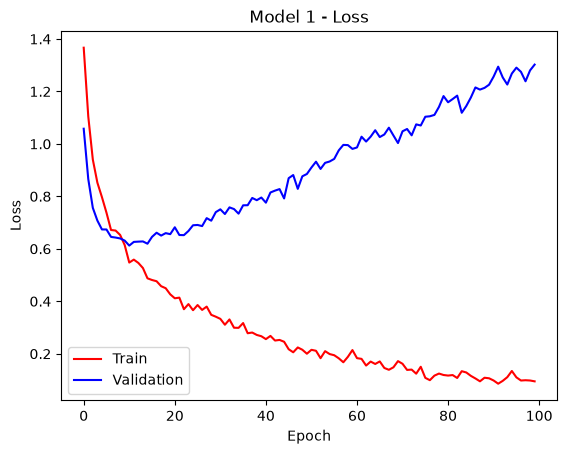

In [23]:
plt.plot(history_1.history["loss"],c="red")
plt.plot(history_1.history["val_loss"],c="blue")

plt.title("Model 1 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

---

In [24]:
model_1es = Sequential()

model_1es.add(Dense(64, activation="relu", input_shape=(61,)))
model_1es.add(Dropout(0.2))

model_1es.add(Dense(32, activation="relu"))
model_1es.add(Dropout(0.2))

model_1es.add(Dense(4, activation="softmax"))

In [25]:
model_1es.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [26]:
early_stop = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [27]:
history_1_es = model_1es.fit(x_train_scaled,y_train_number,validation_data=(x_val_scaled, y_val_number),epochs=100,callbacks=[early_stop],verbose=0)

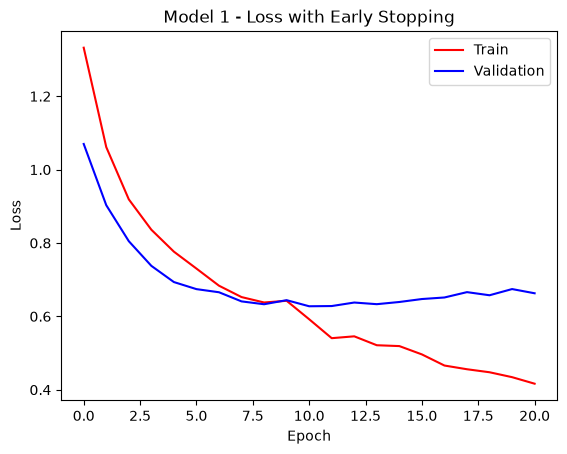

In [28]:
plt.plot(history_1_es.history["loss"], c="red")
plt.plot(history_1_es.history["val_loss"], c="blue")

plt.title("Model 1 - Loss with Early Stopping")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

In [29]:
scores_1_val = model_1es.evaluate(x_val_scaled, y_val_number,verbose=0)
print(f"Model 1 - Validation Loss: {scores_1_val[0]:.4f}")
print(f"Model 1 - Validation Accuracy: {scores_1_val[1] * 100:.2f}%")
print(f"Model 1 - Validation Error: {(1 - scores_1_val[1]) * 100:.2f}%")

Model 1 - Validation Loss: 0.6276
Model 1 - Validation Accuracy: 73.96%
Model 1 - Validation Error: 26.04%


---

In [30]:
model_2 = Sequential()

model_2.add(Dense(32, activation="relu", input_shape=(61,)))
model_2.add(Dropout(0.2))

model_2.add(Dense(16, activation="relu"))
model_2.add(Dropout(0.2))

model_2.add(Dense(4, activation="softmax"))

In [31]:
model_2.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [32]:
early_stop_2 = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [33]:
history_2 = model_2.fit(x_train_scaled,y_train_number,validation_data=(x_val_scaled, y_val_number),epochs=100,callbacks=[early_stop_2],verbose=0)

In [34]:
scores_2_val = model_2.evaluate(x_val_scaled,y_val_number,verbose=0)
print(f"Model 2 - Validation Loss: {scores_2_val[0]:.4f}")
print(f"Model 2 - Validation Accuracy: {scores_2_val[1] * 100:.2f}%")
print(f"Model 2 - Validation Error: {(1 - scores_2_val[1]) * 100:.2f}%")

Model 2 - Validation Loss: 0.6962
Model 2 - Validation Accuracy: 76.04%
Model 2 - Validation Error: 23.96%


---

In [35]:
model_3 = Sequential()

model_3.add(Dense(64, activation="relu", input_shape=(61,)))
model_3.add(Dropout(0.4))

model_3.add(Dense(32, activation="relu"))
model_3.add(Dropout(0.4))

model_3.add(Dense(4, activation="softmax"))

In [36]:
model_3.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [37]:
early_stop_3 = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [38]:
history_3 = model_3.fit(x_train_scaled,y_train_number,validation_data=(x_val_scaled, y_val_number),epochs=100,callbacks=[early_stop_3],verbose=0)

In [39]:
scores_3_val = model_3.evaluate(x_val_scaled,y_val_number,verbose=0)
print(f"Model 3 - Validation Loss: {scores_3_val[0]:.4f}")
print(f"Model 3 - Validation Accuracy: {scores_3_val[1] * 100:.2f}%")
print(f"Model 3 - Validation Error: {(1 - scores_3_val[1]) * 100:.2f}%")

Model 3 - Validation Loss: 0.6021
Model 3 - Validation Accuracy: 71.88%
Model 3 - Validation Error: 28.12%


---

In [40]:
scores_3_test = model_3.evaluate(x_test_scaled,y_test_number,verbose=0)
print(f"Model 3 - Test Loss: {scores_3_test[0]:.4f}")
print(f"Model 3 - Test Accuracy: {scores_3_test[1] * 100:.2f}%")
print(f"Model 3 - Test Error: {(1 - scores_3_test[1]) * 100:.2f}%")

Model 3 - Test Loss: 0.8510
Model 3 - Test Accuracy: 65.79%
Model 3 - Test Error: 34.21%


In [41]:
y_pred_3_test = model_3.predict(x_test_scaled, verbose=0)
y_pred_3_test = np.argmax(y_pred_3_test, axis=1)

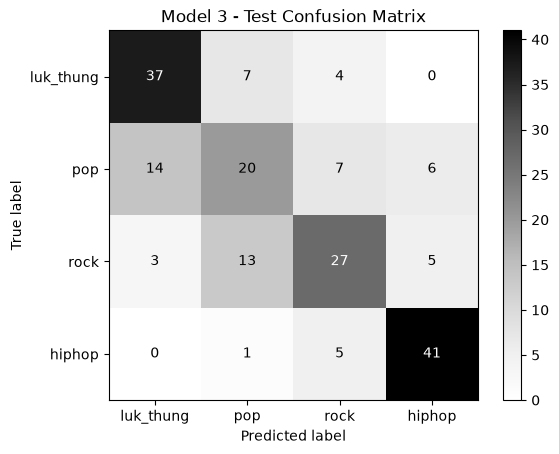

In [42]:
ConfusionMatrixDisplay.from_predictions(y_test_number,y_pred_3_test,labels=[0, 1, 2, 3],display_labels=labels,cmap="Greys")
plt.title("Model 3 - Test Confusion Matrix")
plt.show()

In [43]:
print(classification_report(y_test_number,y_pred_3_test,target_names=labels))

              precision    recall  f1-score   support

   luk_thung       0.69      0.77      0.73        48
         pop       0.49      0.43      0.45        47
        rock       0.63      0.56      0.59        48
      hiphop       0.79      0.87      0.83        47

    accuracy                           0.66       190
   macro avg       0.65      0.66      0.65       190
weighted avg       0.65      0.66      0.65       190



---

In [44]:
model_3.save("Saved/model_3.h5")